<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Practice Assignment - Part 1: Analyzing wildfire activities in Australia** 

Estimated time needed: **40** minutes


# __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    <li>
        <a href="#Setup">Setup</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Installing Required Libraries</a></li>
            <li><a href="#Importing-Required-Libraries">Importing Required Libraries</a></li>
    </li>
    <li>
        <a href="#Dataset">Dataset</a>
    </li>
    <li><a href="#Importing Dataset">Importing Dataset</a></li>
    <li><a href="#Practice Tasks">Practice Tasks</a></li>
   


---


# Objectives

After completing this lab you will be able to:

 - Use visualization libraries such as Matplotlib, Pandas, Seaborn and Folium to create informative plots and charts 


---


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


### Installing Required Libraries

The following required libraries are pre-installed in the Skills Network Labs environment. However, if you run this notebook commands in a different Jupyter environment (e.g. Watson Studio or Ananconda), you will need to install these libraries by removing the `#` sign before `%pip` in the code cell below.


In [ ]:
# All Libraries required for this lab are listed below. The libraries pre-installed on Skills Network Labs are commented.
#%pip install -qy pandas==1.3.4 numpy==1.21.4 seaborn==0.9.0 matplotlib==3.5.0 folium
# Note: If your environment doesn't support "%pip install", use "!mamba install"

In [1]:
%pip install seaborn
%pip install folium

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
%matplotlib inline

---


# Dataset

**Historical Wildfires**

This wildfire dataset contains data on fire activities in Australia starting from 2005. Additional information can be found [here](https://earthdata.nasa.gov/earth-observation-data/near-real-time/firms/c6-mcd14dl).

Variables

- Region: the 7 regions
- Date: in UTC and provide the data for 24 hours ahead
- Estimated_fire_area: daily sum of estimated fire area for presumed vegetation fires with a confidence > 75% for a each region in km2
- Mean_estimated_fire_brightness: daily mean (by flagged fire pixels(=count)) of estimated fire brightness for presumed vegetation fires with a confidence level > 75% in Kelvin
- Mean_estimated_fire_radiative_power: daily mean of estimated radiative power for presumed vegetation fires with a confidence level > 75% for a given region in megawatts
- Mean_confidence: daily mean of confidence for presumed vegetation fires with a confidence level > 75%
- Std_confidence: standard deviation of estimated fire radiative power in megawatts
- Var_confidence: Variance of estimated fire radiative power in megawatts
- Count: daily numbers of pixels for presumed vegetation fires with a confidence level of larger than 75% for a given region
- Replaced: Indicates with an Y whether the data has been replaced with standard quality data when they are available (usually with a 2-3 month lag). Replaced data has a slightly higher quality in terms of locations


---


### Importing Data


In [9]:
# 导入数据：将数据命名为 Australian_wildfire:
import pandas as pd
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv"
Australian_wildfire = pd.read_csv(URL)
print('Data read into a pandas dataframe!')
# 从下面的结果显示，数据导入成功。

Data read into a pandas dataframe!


Let's look at some samples rows from the dataset we loaded:


In [10]:
# 进一步打印数据的前五行，检查数据是否成功导入：
Australian_wildfire.head(5)
# 从下面的结果来看，数据确实已经成功导入。

,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced
0,NSW,1/4/2005,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R
1,NSW,1/5/2005,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R
2,NSW,1/6/2005,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R
3,NSW,1/7/2005,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R
4,NSW,1/8/2005,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R


---


Let's verify the column names and the data type of each variable


In [11]:
#Column names
# 进一步检查数据的列的名字。对数据集使用属性columns:
Australian_wildfire.columns

Index(['Region', 'Date', 'Estimated_fire_area',
       'Mean_estimated_fire_brightness', 'Mean_estimated_fire_radiative_power',
       'Mean_confidence', 'Std_confidence', 'Var_confidence', 'Count',
       'Replaced'],
      dtype='str')

In [13]:
#data type
# 进一步检查每一列的数据类型：对数据集使用属性dtypes:
Australian_wildfire.dtypes

Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
dtype: object

Notice the type of 'Date' is object, let's convert it to 'datatime' type and also let's extract 'Year' and 'Month' from date and include in the dataframe as separate columns


In [17]:
import datetime as dt
# 注意'Date'的类型是对象，让我们将其转换为'datetime'类型，
# 并从日期中提取'年份'和'月份'，并作为单独的列包含在数据框中。
Australian_wildfire['Year'] = pd.to_datetime(Australian_wildfire['Date']).dt.year
Australian_wildfire['Month'] = pd.to_datetime(Australian_wildfire['Date']).dt.month

**Verify the columns again**


In [20]:
#verify the columns again
# 再一次打印column names，去检查上面的操作，是否已经提取出 Year 和 Month：
Australian_wildfire.columns
# 从输出结果来看，Year 和 Month已经加入到列名里，操作成功。

Index(['Region', 'Date', 'Estimated_fire_area',
       'Mean_estimated_fire_brightness', 'Mean_estimated_fire_radiative_power',
       'Mean_confidence', 'Std_confidence', 'Var_confidence', 'Count',
       'Replaced', 'Year', 'Month'],
      dtype='str')

In [21]:
# 同时，打印数据类型，检查是否Date已经转换为datetime类型：
Australian_wildfire.dtypes
# Date列数据类型变成了 string，说明也操作成功：

Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
Year                                     int32
Month                                    int32
dtype: object

<details>
    <summary>Click here for Solution</summary>

```python
    df.dtypes
```

</details>


---


## Practice Tasks


### TASK 1.1: Let's try to understand the change in average estimated fire area over time <br>(use pandas to plot)


<details>
    <summary>Click here for a Hint</summary>
You will be required to group the year for 'Estimated_fire_area' (taking its mean)<br>Then use df.plot() on it to create a line graph

</details>


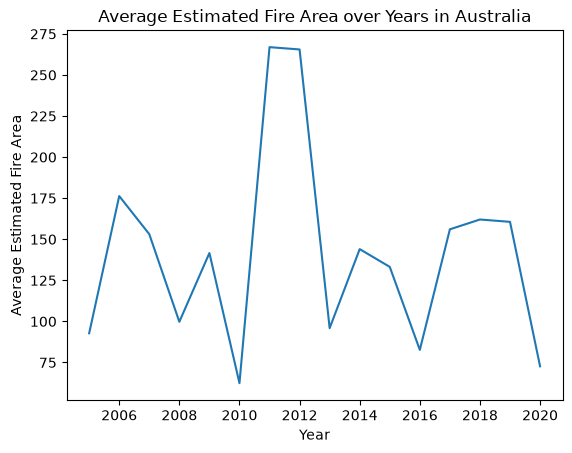

In [22]:
# TODO
# 练习任务
# 任务1.1: 让我们尝试理解，平均估计火灾面积随时间的变化 (使用 pandas进行绘图 )
# 先对着火面积，按照年份求和：将变量命名为 sum_Australian_wildfire:
sum_Australian_wildfire = Australian_wildfire.groupby('Year')['Estimated_fire_area']
# 然后求年均着火面积：将变量命名为 avg_Australian_wildfire:
avg_Australian_wildfire = sum_Australian_wildfire.mean()
# 下一步，画图：因为是折线图，所以kind=line：
avg_Australian_wildfire.plot( kind='line' )
# 设置图表标题、行标题和列标题：
plt.title('Average Estimated Fire Area over Years in Australia')
plt.ylabel('Average Estimated Fire Area')
plt.xlabel('Year')
# 最后，一步到位画图：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
    plt.figure(figsize=(12, 6))
    # Grouping the data by 'Year' and calculating the mean of 'Estimated_fire_area'
    df_new = df.groupby('Year')['Estimated_fire_area'].mean()
    # Plotting the data
    df_new.plot(x=df_new.index, y=df_new.values)
    plt.xlabel('Year')
    plt.ylabel('Average Estimated Fire Area (km²)')
    plt.title('Estimated Fire Area over Time')
    plt.show()
```

</details>


---


### TASK 1.2: You can notice the peak in the plot between 2010 to 2013. Let's narrow down our finding, by plotting the estimated fire area for year grouped together with month.


<details>
    <summary>Click here for a Hint</summary>
You will be required to group the year and month for 'Estimated_fire_area' (taking its mean)<br>Then use df.plot() on it to create a line graph

</details>


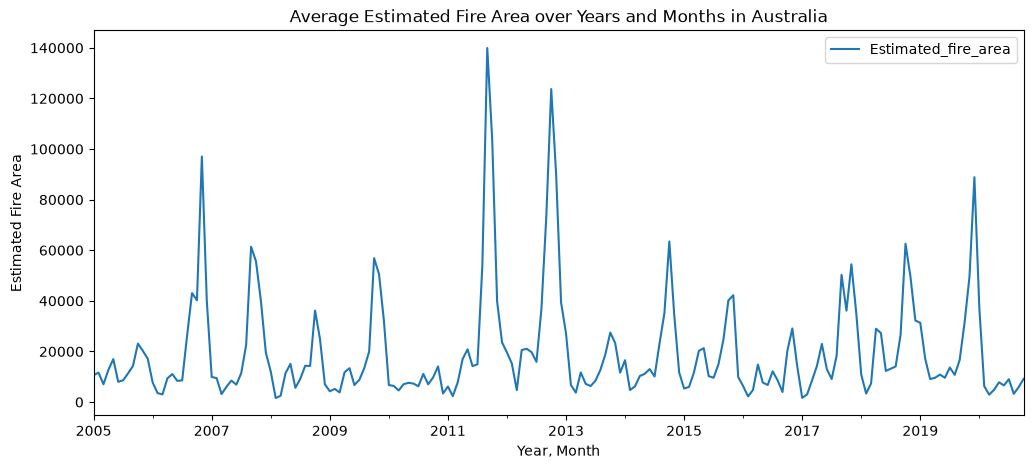

In [25]:
# TODO
# 任务1.2:你可以注意到图表中2010年至2013年间有一个峰值。
# 让我们通过将估计的火灾面积按年份和月份分组来缩小我们的发现范围。

# 先按 Year, Month 分组求和
sum_Australian_wildfire_A = Australian_wildfire.groupby(['Year','Month'])['Estimated_fire_area'].sum().reset_index()

# 拼接成日期，用当月1号代表这个年月
sum_Australian_wildfire_A['date'] = pd.to_datetime(
    sum_Australian_wildfire_A[['Year','Month']].assign( Day=1 )
)

# 画图，x轴是真正的时间
sum_Australian_wildfire_A.plot(x = 'date', y = 'Estimated_fire_area', kind = 'line', figsize = (12,5))
plt.title('Average Estimated Fire Area over Years and Months in Australia')
plt.ylabel('Estimated Fire Area')
plt.xlabel('Year, Month')
# 一步到位画图：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
    # Grouping the data by both 'Year' and 'Month', and calculating the mean of 'Estimated_fire_area'
    df_new = df.groupby(['Year','Month'])['Estimated_fire_area'].mean()
    # Plotting the data
    df_new.plot(x=df_new.index, y=df_new.values)
    plt.xlabel('Year, Month')
    plt.ylabel('Average Estimated Fire Area (km²)')
    plt.title('Estimated Fire Area over Time')
    plt.show()
```

</details>


This plot represents that the estimated fire area was on its peak after 2011, April and before 2012. You can verify on google/news, this was the time of maximum wildfire hit in Austrailia


---


### TASK 1.3: Let's have an insight on the distribution of mean estimated fire brightness across the regions<br> use the functionality of seaborn to develop a barplot


before starting with the plot, why not know the regions mentioned in the dataset?. <br>Make use of unique() to identify the regions in the dataset (apply it on series only)


In [26]:
# 让我们通过使用seaborn的功能来绘制柱状图，了解各区域平均估计火光亮度的分布情况。
# 在开始绘图之前，为什么不先了解数据集中提到的区域呢?
# 使用unique()函数识别数据集中的区域(仅应用于series)
Australian_wildfire['Region'].unique()

<ArrowStringArray>
['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']
Length: 7, dtype: str

<details>
    <summary>Click here for a Hint</summary>
you need to plot reions on x-axis and the 'Mean_estimated_fire_brightness' on y-axis.<br>Title it as 'Distribution of Mean Estimated Fire Brightness across Regions'
</details>


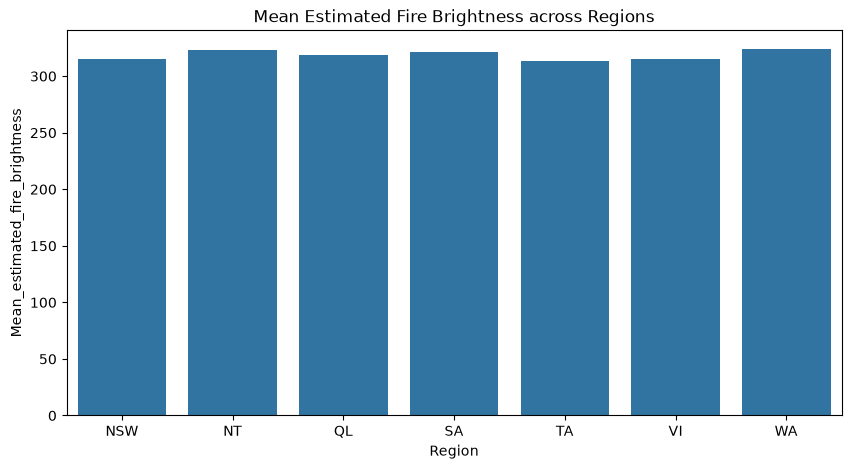

In [29]:
#TODO
# 导入seaborn画图所需要的包：
import seaborn as sns
import matplotlib.pyplot as plt

# 按区域分组，计算每个区域的平均火光亮度。
# 然后将新的变量命名为：Mean_fire_brightness_in_regions:
Mean_fire_brightness_in_regions = Australian_wildfire.groupby('Region')['Mean_estimated_fire_brightness'].mean().reset_index()

# seaborn barplot
# 绘制柱状图：
plt.figure( figsize = (10,5))
# 设置图表标题、行标题、列标题：
sns.barplot( data = Mean_fire_brightness_in_regions , x = 'Region', y = 'Mean_estimated_fire_brightness')
plt.title('Mean Estimated Fire Brightness across Regions')

# 一步到位，出图：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a bar plot using seaborn to visualize the distribution of mean estimated fire brightness across regions
plt.figure(figsize=(10, 6))
# Using seaborn's barplot function to create the plot
sns.barplot(data=df, x='Region', y='Mean_estimated_fire_brightness')
plt.xlabel('Region')
plt.ylabel('Mean Estimated Fire Brightness (Kelvin)')
plt.title('Distribution of Mean Estimated Fire Brightness across Regions')
plt.show()
```
</details>


---


### TASK 1.4: Let's find the portion of count of pixels for presumed vegetation fires vary across regions<br> we will develop a pie chart for this


<details>
    <summary>Click here for a Hint</summary>
First you will  be required to group the data on region and find the sum of count
</details>


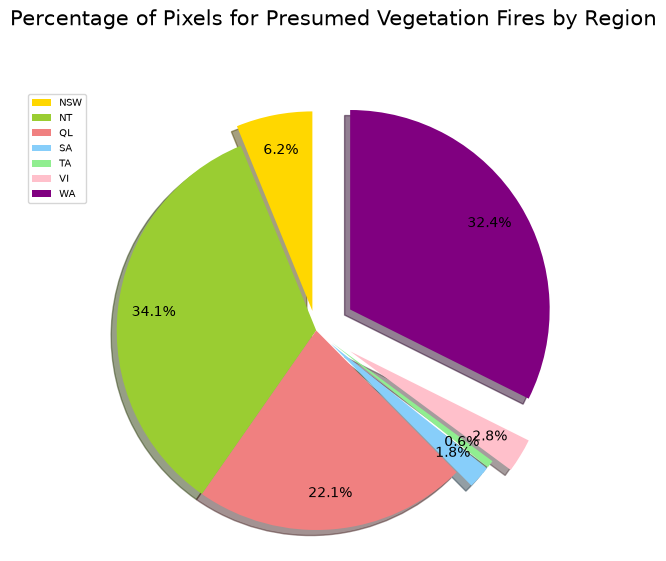

In [32]:
# 任务1.4:
# 让我们找出假设的植被火灾像素数量在不同地区的变化部分，
# 我们将为此制作一个饼图。
# 首先，将火灾像素数量按照地区分组 groupby 汇总sum，将新的变量命名为 fire_pixels_in_regions：
fire_pixels_in_regions = Australian_wildfire.groupby('Region')['Count'].sum()
colors_list = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink', 'purple']
# ratio for each continent with which to offset each wedge.
explode_list = [0.1, 0, 0, 0.1, 0.1, 0.2, 0.2] 

# 然后，画图！设置各种参数：
fire_pixels_in_regions.plot(
                            kind = 'pie', # 绘制饼图，所以 kind = pie
                            figsize = (8, 6),
                            autopct = '%1.1f%%', 
                            startangle = 90,    
                            shadow = True,       
                            labels = None,         # turn off labels on pie chart
                            pctdistance = 0.82,    # the ratio between the center of each pie slice and the start of the text generated by autopct 
                            colors = colors_list,  # add custom colors
                            explode = explode_list # 'explode' lowest 3 continents
                            )

# 接下来依然是设置图表标题、图例、和图形的形状（标准圆形）：
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region', y=1.12, fontsize = 15) 
plt.axis('equal') 
plt.legend( labels = fire_pixels_in_regions.index, loc='upper left', fontsize = 7) 
# 最后，打印出新的图：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a pie chart to visualize the portion of count of pixels for presumed vegetation fires across regions
plt.figure(figsize=(10, 6))
# Grouping the data by region and summing the counts
region_counts = df.groupby('Region')['Count'].sum()
# Creating the pie chart using plt.pie function
# Labels are set to the region names, and autopct is used to display percentage
plt.pie(region_counts, labels=region_counts.index, autopct='%1.1f%%')
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region')
plt.axis('equal')
plt.show()
```
</details>


### TASK 1.5: See the percentage on the pie is not looking so good as it is overlaped for Region SA, TA, VI 

remove the autopct from pie function and pass the following to plt.legend() after plt.title() <br>
`[(i,round(k/region_counts.sum()*100,2)) for i,k in zip(region_counts.index, region_counts)]`


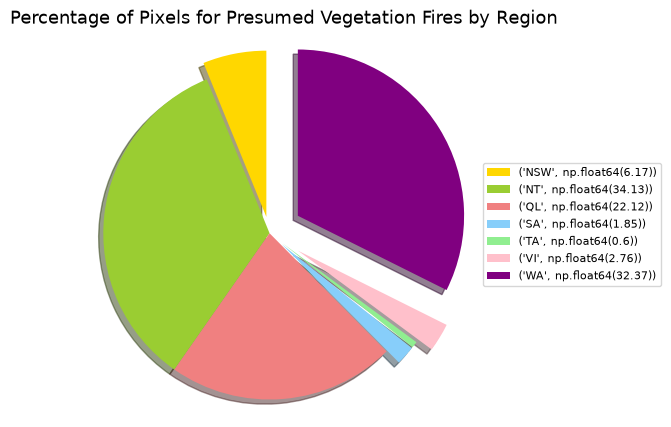

In [37]:
#TODO
# 任务1.5:查看饼图上的百分比看起来不太好，因为区域 SA、TA和 VI重叠了。
# 从pie函数中移除 autopct，并在 plt.title之后将以下内容传递给 plt.legend()。
#前面这个部分什么都不用改：
region_counts = Australian_wildfire.groupby('Region')['Count'].sum()
colors_list = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink', 'purple']
explode_list = [0.1, 0, 0, 0.1, 0.1, 0.2, 0.2]
# 主要改动是，删除了 autopct = '%1.1f%%',然后令 legend_labels=[(i,round(k/region_counts.sum()*100,2)) for i,k in zip(region_counts.index, region_counts)]
region_counts.plot(
    kind = 'pie',
    figsize = (5,5),
    startangle = 90,
    shadow = True,
    labels = None,
    colors = colors_list,
    explode = explode_list
)
plt.title('Percentage of Pixels for Presumed Vegetation Fires by Region', fontsize=13)
plt.axis('equal')
# 题目给的列表推导式，拼成图例标签
legend_labels = [(i, round(k/region_counts.sum()*100,2)) for i,k in zip(region_counts.index, region_counts)]
# 设置图例：
plt.legend( labels = legend_labels, loc = "center left", bbox_to_anchor = (1, 0.5), fontsize = 8 )
# 最后，绘制出图：
plt.show()

---


### TASK 1.6: Let's try to develop a histogram of the mean estimated fire brightness<br> Using Matplotlib to create the histogram


<details>
    <summary>Click here for a Hint</summary>
    Call plt.hist() and pass df['Mean_estimated_fire_brightness'] as x
</details>


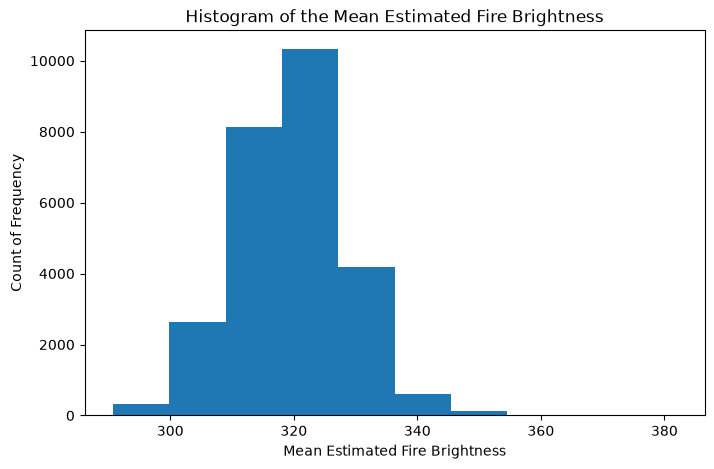

In [40]:
#TODO
# 任务1.6:让我们尝试使用 Matplotlib，创建一个平均估计的火光亮度直方图。
# 直接画图：
# 因为是直方图，所以 kind = hist；
Australian_wildfire['Mean_estimated_fire_brightness'].plot( 
    kind = 'hist', 
    figsize = (8, 5))
# 然后，设置图表标题、行标题和列标题：
plt.title('Histogram of the Mean Estimated Fire Brightness')
plt.ylabel('Count of Frequency')
plt.xlabel('Mean Estimated Fire Brightness')
# 最后一步到位展示绘制的图像：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a histogram to visualize the distribution of mean estimated fire brightness
plt.figure(figsize=(10, 6))
# Using plt.hist to create the histogram
# Setting the number of bins to 20 for better visualization
plt.hist(x=df['Mean_estimated_fire_brightness'], bins=20)
plt.xlabel('Mean Estimated Fire Brightness (Kelvin)')
plt.ylabel('Count')
plt.title('Histogram of Mean Estimated Fire Brightness')
plt.show()
```
</details>


### TASK 1.7: What if we need to understand the distribution of estimated fire brightness across regions? Let's use the functionality of seaborn and  pass region as hue


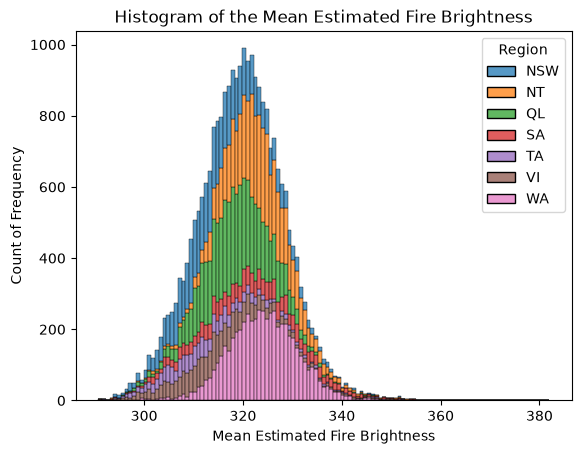

In [42]:
# 任务1.7:如果我们需要了解估计的火光亮度在不同区域的分布情况，该如何处理?
# 让我们使用seabom的功能，并将 region作为 hue参数传递。
import seaborn as sns
# 首先，按照地区分组统计火光亮度。将新变量命名为：region_fire_brightness:
region_fire_brightness = Australian_wildfire.groupby('Region')['Mean_estimated_fire_brightness'].sum()
# 然后，画图，依然是直方图：
sns.histplot( data = Australian_wildfire, x = 'Mean_estimated_fire_brightness', hue = 'Region', multiple = 'stack')
# 然后，设置图表标题、行标题和列标题：
plt.title('Histogram of the Mean Estimated Fire Brightness')
plt.ylabel('Count of Frequency')
plt.xlabel('Mean Estimated Fire Brightness')
# 最后一步到位展示绘制的图像：
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a histogram to visualize the distribution of mean estimated fire brightness across regions using Seaborn
# Using sns.histplot to create the histogram
# Specifying the DataFrame (data=df) and the column for the x-axis (x='Mean_estimated_fire_brightness')
# Adding hue='Region' to differentiate the distribution across regions
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region')
plt.show()
```
</details>


### looks better!, now include the parameter `multiple='stack'` in the histplot() and see the difference. Include labels and titles as well


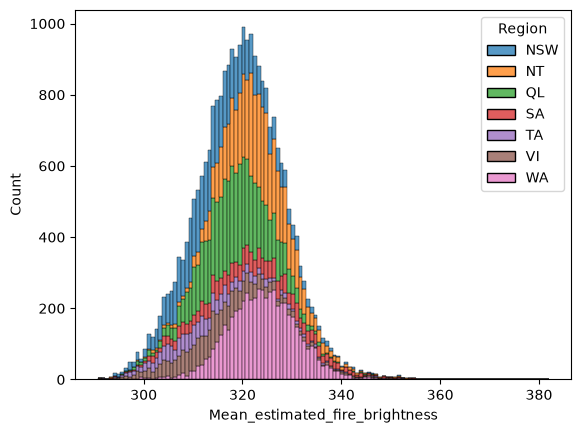

In [44]:
# 看起来更好了! 
# 现在在histplot()中包含参数multiple='stack'，并查看差异。
# 同时添加标签和标题。
sns.histplot( data = Australian_wildfire, x ='Mean_estimated_fire_brightness', hue = 'Region', multiple = 'stack' )
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Creating a stacked histogram to visualize the distribution of mean estimated fire brightness across regions using Seaborn
# Using sns.histplot to create the stacked histogram
# Specifying the DataFrame (data=df) and the column for the x-axis (x='Mean_estimated_fire_brightness')
# Adding hue='Region' to differentiate the distribution across regions
# Setting multiple='stack' to stack the histograms for different regions
sns.histplot(data=df, x='Mean_estimated_fire_brightness', hue='Region', multiple='stack')
plt.show()
```
</details>


---


### TASK 1.8: Let's try to find if there is any correlation between mean estimated fire radiative power and mean confidence level?


<details>
    <summary>Click here for a Hint</summary>
    Call plt.scatter() <br> or use the sns.scatterplot()
</details>


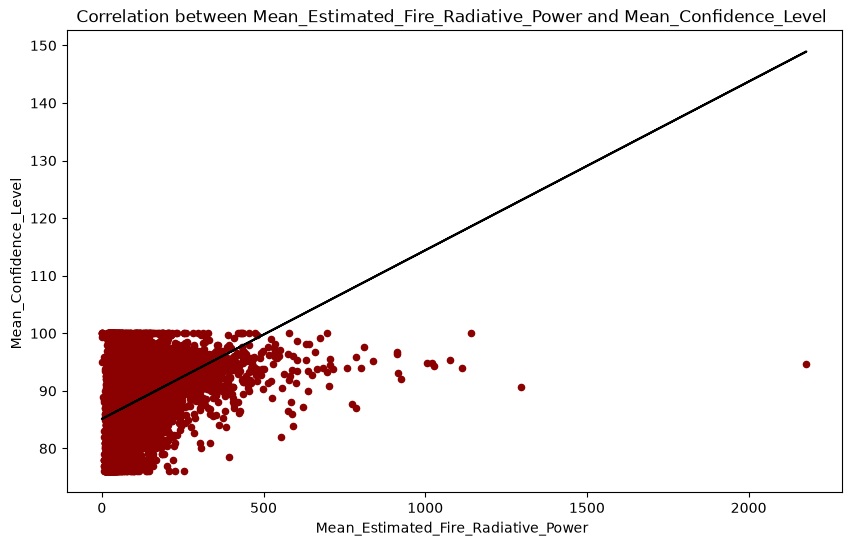

slope: 0.029292520045941794
intercept: 85.12525789119425


In [50]:
# 任务1.8: 让我们尝试找出：平均估计的火灾辐射功率 与 平均置信水平 之间是否存在相关性?
# Mean_estimated_fire_radiative_power、Mean_confidence
# 一般来说，找相关性使用 scatterplot 带上 趋势线 会比较好：
# 因为是 scatterplot，所以 kind = scatter，x是 辐射功率，y是置信水平：
x = Australian_wildfire['Mean_estimated_fire_radiative_power']
y = Australian_wildfire['Mean_confidence']
# 然后画图！
Australian_wildfire.plot( kind = 'scatter', 
                          x = 'Mean_estimated_fire_radiative_power',
                          y = 'Mean_confidence', 
                          figsize = (10, 6), 
                          color = 'darkred' 
                        )

# 然后就是设置图表标题、行标题和列标题：
plt.title('Correlation between Mean_Estimated_Fire_Radiative_Power and Mean_Confidence_Level ')
plt.xlabel('Mean_Estimated_Fire_Radiative_Power ')
plt.ylabel('Mean_Confidence_Level ')

# 下一步就是绘制刚刚的参考线，这个线遵循一次线性回归：y要写成 y = model_fit[0]+model_fit[1]*x:
# plot line of best fit
# 线性回归拟合，计算model_fit
model_fit = np.polyfit(x, y, 1)
# 绘制拟合直线
plt.plot(x, model_fit[0] * x + model_fit[1], color = 'black')
# 标注公式，位置调整到图内合适地方
plt.annotate('y={0:.2f} x + {1:.2f}'.format(model_fit[0], model_fit[1]), xy=(50, 0.85))
# 打印图表：
plt.show()

# 打印拟合参数
print("slope:", model_fit[0])
print("intercept:", model_fit[1])

In [ ]:
Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
Year                                     int32
Month                                    int32

<details>
    <summary>Click here for Solution</summary>

```python
    # Creating a scatter plot to visualize the relationship between mean estimated fire radiative power and mean  confidence using Seaborn
    plt.figure(figsize=(8, 6))
    # Using sns.scatterplot to create the scatter plot
    # Specifying the DataFrame (data=df) and the columns for the x-axis (x='Mean_confidence') and y-axis            (y='Mean_estimated_fire_radiative_power')
    sns.scatterplot(data=df, x='Mean_confidence', y='Mean_estimated_fire_radiative_power')
    plt.xlabel('Mean Estimated Fire Radiative Power (MW)')
    plt.ylabel('Mean Confidence')
    plt.title('Mean Estimated Fire Radiative Power vs. Mean Confidence')
    plt.show()
```
</details>


---


### TASK 1.9: Let's mark these seven regions on the Map of Australia using Folium
<br> we have created a dataframe for you containing the regions, their latitudes and longitudes. <br> For australia use [-25, 135] as location to create the map


In [51]:
# 1.9:让我们使用Folium在澳大利亚地图上标记这七个区域。
# 我们为你创建了一个包含区域、纬度和经度的数据框。
# 对于澳大利亚，使用[-25,135]作为位置来创建地图。

region_data = {'region':['NSW','QL','SA','TA','VI','WA','NT'], 'Lat':[-31.8759835,-22.1646782,-30.5343665,-42.035067,-36.5986096,-25.2303005,-19.491411], 
               'Lon':[147.2869493,144.5844903,135.6301212,146.6366887,144.6780052,121.0187246,132.550964]}
reg = pd.DataFrame( region_data )
reg

,region,Lat,Lon
0,NSW,-31.875984,147.286949
1,QL,-22.164678,144.584490
2,SA,-30.534367,135.630121
3,TA,-42.035067,146.636689
4,VI,-36.598610,144.678005
5,WA,-25.230300,121.018725
6,NT,-19.491411,132.550964


In [56]:
# 按题目要求：中心 [-25,135]
Australia_map = folium.Map( location = [-25, 135], zoom_start = 4 )
# 建立标记组
region_group = folium.map.FeatureGroup()
# 循环遍历 reg 的 Lat、Lon、region
for lat, lon, r_name in zip( reg['Lat'], reg['Lon'], reg['region'] ):
    region_group.add_child(
        folium.CircleMarker(
            [lat, lon],
            radius = 7,
            color = 'red',
            fill = True,
            fill_color = 'red',
            fill_opacity = 0.7
        )
    )
# 把标记组加到地图：
Australia_map.add_child( region_group )
# 弹出文字：
# 如果你想要鼠标点上去显示州名，换成这个版本的循环：
for lat, lon, r_name in zip( reg['Lat'], reg['Lon'], reg['region']):
     folium.Marker( location = [lat, lon], popup = r_name ).add_to( Australia_map )
# 显示地图
Australia_map

<details>
    <summary>Click here for Solution</summary>

```python
# instantiate a feature group 
aus_reg = folium.map.FeatureGroup()

# Create a Folium map centered on Australia
Aus_map = folium.Map(location=[-25, 135], zoom_start=4)

# loop through the region and add to feature group
for lat, lng, lab in zip(reg.Lat, reg.Lon, reg.region):
    aus_reg.add_child(
        folium.features.CircleMarker(
            [lat, lng],
            popup=lab,
            radius=5, # define how big you want the circle markers to be
            color='red',
            fill=True,
            fill_color='blue',
            fill_opacity=0.6
        )
    )

# add incidents to map
Aus_map.add_child(aus_reg)
```
</details>


---


# Congratulations! You have completed the lab


## Authors


[Dr. Pooja](author_link)


#### Copyright © 2023 IBM Corporation. All rights reserved.
```{toggle}## Change Log
```


```{toggle}|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
```

```{toggle}|-|-|-|-|
```
```{toggle}|2023-06-281|0.2|Dr. Pooja|Initial Lab Creation|
```
```{toggle}|2023-05-01|0.1|Shengkai|Create Lab Template|
```
